# 04 — Walker circulation index (ω500)

Walker circulation strength (Methods, Eq. 4):

ω500,E−W = ω500,E − ω500,W, with box means (cos-latitude weighted) over
the western (5°S–5°N, 80°E–160°E) and eastern (5°S–5°N, 160°W–80°W) Pacific.
Positive values = stronger Walker circulation.

1. Control-run climatology: map and box means.
2. Write the climatology to `complete_climatology.csv`.
3. Quick check: ω500 maps of the three runs for one event.
4. All 23 events × 3 runs → `complete_wc_analysis.csv` (feeds Figure 2).
5. Quick check: ω500 anomaly maps (run − climatology) for the same event.

Box means are raw values for each run; anomalies relative to the control
run are formed in `08`.

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Rectangle

WEST_BOX = dict(lat=slice(-5, 5), lon=slice(80, 160))
EAST_BOX = dict(lat=slice(-5, 5), lon=slice(200, 280))
RUN_SUFFIX = {"Full Run": "FULL", "Uniform Run": "UNIFORM", "Pattern Run": "PATTERN"}


def box_mean(field, box):
    """Cos-latitude weighted box mean; works for ascending or descending latitude."""
    lat_lo, lat_hi = box["lat"].start, box["lat"].stop
    lat_slice = slice(lat_lo, lat_hi) if field.lat[0] < field.lat[-1] else slice(lat_hi, lat_lo)
    sub = field.sel(lat=lat_slice, lon=box["lon"])
    weights = np.cos(np.deg2rad(sub.lat))
    return sub.weighted(weights).mean(["lat", "lon"]).item()


def event_dir(event):
    return cfg.ECHAM_OUTPUT_ELNINO_DIR if event == "El Niño" else cfg.ECHAM_OUTPUT_LANINA_DIR


def omega500_field(atm_path, period=None):
    """Time-mean ω at 500 hPa in Pa/s (optionally over a time window)."""
    omega = xr.open_dataset(atm_path)["omega"]
    scale = 100.0 if omega.attrs.get("units") in ["hPa/s", "hPa s-1"] else 1.0   # read units before averaging
    if period is not None:
        omega = omega.sel(time=slice(*period))
    return scale * omega.mean("time").sel(plev=50000, method="nearest")


def show_with_boxes(field, title, vmin=-0.08, vmax=0.08):
    plt.figure(figsize=(9, 4))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.coastlines()
    field.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", vmin=vmin, vmax=vmax)
    for box, color in [(WEST_BOX, "red"), (EAST_BOX, "blue")]:
        lon0, lon1 = box["lon"].start, box["lon"].stop
        lat0, lat1 = box["lat"].start, box["lat"].stop
        ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, edgecolor=color, facecolor="none",
                               linestyle="--", linewidth=1.5, transform=ccrs.PlateCarree()))
    plt.title(title)
    plt.show()

## Step 1 — climatology (control run, `cfg.CLIM_PERIOD`)

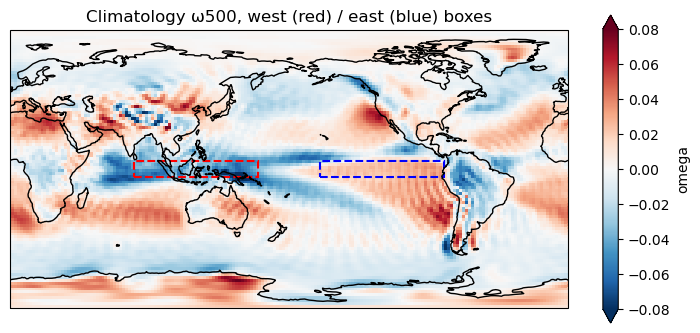

climatology east-west omega500 = 0.06801 Pa/s


In [2]:
climatology = omega500_field(cfg.CLIMATOLOGY_ATM_PATH, period=cfg.CLIM_PERIOD)
show_with_boxes(climatology, "Climatology ω500, west (red) / east (blue) boxes")

clim_east = box_mean(climatology, EAST_BOX)
clim_west = box_mean(climatology, WEST_BOX)
print(f"climatology east-west omega500 = {clim_east - clim_west:.5f} Pa/s")

## Step 2 — write the climatology to the climatology table

In [3]:
def update_climatology_csv(new_values):
    if os.path.exists(cfg.CLIMATOLOGY_CSV_PATH):
        clim_df = pd.read_csv(cfg.CLIMATOLOGY_CSV_PATH)
        if len(clim_df) == 0:
            clim_df = pd.DataFrame([{}])
    else:
        clim_df = pd.DataFrame([{}])
    for col, val in new_values.items():
        clim_df.loc[0, col] = val
    os.makedirs(cfg.ANALYSIS_DIR, exist_ok=True)
    clim_df.to_csv(cfg.CLIMATOLOGY_CSV_PATH, index=False)


update_climatology_csv({
    "east_mean_omega500": clim_east, "west_mean_omega500": clim_west,
    "eastminuswest_omega500": clim_east - clim_west, "westminuseast_omega500": clim_west - clim_east,
})
print("saved", cfg.CLIMATOLOGY_CSV_PATH)

saved /work/mh1421/m301201/enso-tug-of-war/walker-tug-of-war/data/complete_climatology.csv


## Step 3 — quick check: one event, all three runs

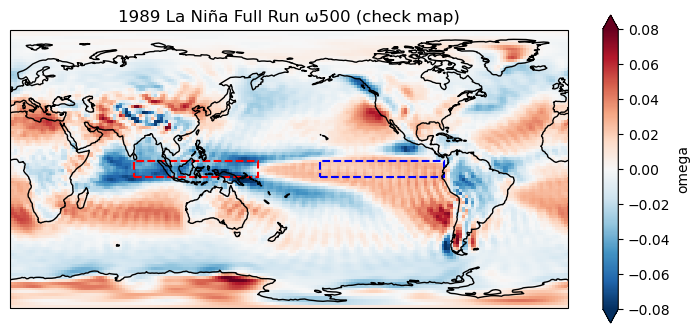

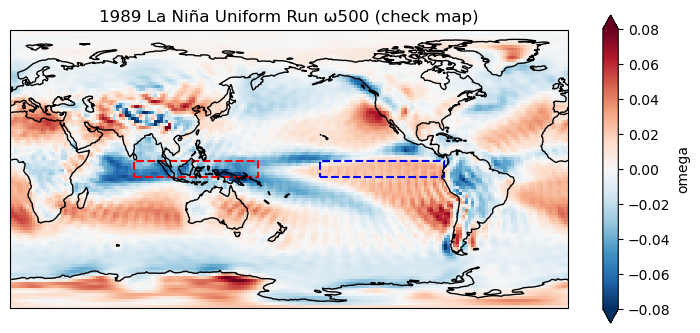

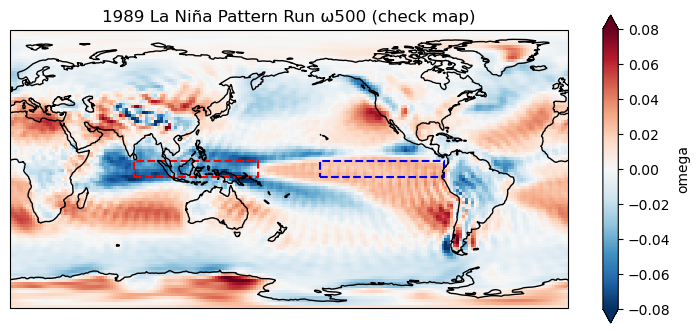

In [4]:
CHECK_EVENT_YEAR = 1989          # <- any event year
CHECK_EVENT_TYPE = "La Niña"     # must match the folder the year's data lives in

for run in ["Full Run", "Uniform Run", "Pattern Run"]:
    check_path = os.path.join(event_dir(CHECK_EVENT_TYPE), f"{CHECK_EVENT_YEAR}_{RUN_SUFFIX[run]}_echam6_ATM_mm_1976-1999.nc")
    if os.path.exists(check_path):
        show_with_boxes(omega500_field(check_path), f"{CHECK_EVENT_YEAR} {CHECK_EVENT_TYPE} {run} ω500 (check map)")
    else:
        print(f"missing {check_path} -- change CHECK_EVENT_YEAR/CHECK_EVENT_TYPE above")

## Step 4 — all events → analysis table

In [5]:
df = pd.read_csv(cfg.ANALYSIS_CSV_PATH)

for col in ["east_mean_omega500", "west_mean_omega500", "eastminuswest_omega500", "westminuseast_omega500"]:
    if col not in df.columns:
        df[col] = np.nan

for _, row in df.drop_duplicates(subset=["Year", "Run"]).iterrows():
    year, run, event = row["Year"], row["Run"], row["Event"]
    path = os.path.join(event_dir(event), f"{year}_{RUN_SUFFIX[run]}_echam6_ATM_mm_1976-1999.nc")
    if not os.path.exists(path):
        print(f"missing file for {year} {run} -- skipping")
        continue

    omega500 = omega500_field(path)
    east = box_mean(omega500, EAST_BOX)
    west = box_mean(omega500, WEST_BOX)
    mask = (df["Year"] == year) & (df["Run"] == run)
    df.loc[mask, "east_mean_omega500"] = east
    df.loc[mask, "west_mean_omega500"] = west
    df.loc[mask, "eastminuswest_omega500"] = east - west
    df.loc[mask, "westminuseast_omega500"] = west - east
    print(f"{year} {run}: east-west omega500 = {east - west:.5f}")

df.to_csv(cfg.ANALYSIS_CSV_PATH, index=False)
print("saved", cfg.ANALYSIS_CSV_PATH)

1983 Full Run: east-west omega500 = 0.01632
1983 Uniform Run: east-west omega500 = 0.06976
1983 Pattern Run: east-west omega500 = 0.01268
1984 Full Run: east-west omega500 = 0.07110
1984 Uniform Run: east-west omega500 = 0.06749
1984 Pattern Run: east-west omega500 = 0.06959
1985 Full Run: east-west omega500 = 0.07707
1985 Uniform Run: east-west omega500 = 0.06832
1985 Pattern Run: east-west omega500 = 0.07601
1986 Full Run: east-west omega500 = 0.07315
1986 Uniform Run: east-west omega500 = 0.06767
1986 Pattern Run: east-west omega500 = 0.07352
1987 Full Run: east-west omega500 = 0.04938
1987 Uniform Run: east-west omega500 = 0.06761
1987 Pattern Run: east-west omega500 = 0.05035
1988 Full Run: east-west omega500 = 0.05879
1988 Uniform Run: east-west omega500 = 0.06813
1988 Pattern Run: east-west omega500 = 0.05869
1989 Full Run: east-west omega500 = 0.07383
1989 Uniform Run: east-west omega500 = 0.06677
1989 Pattern Run: east-west omega500 = 0.07455
1992 Full Run: east-west omega500 

## Step 5 — quick check: ω500 anomaly maps (run − climatology), 30°S–30°N

In [6]:
def restrict_tropics(field, lat_bound=30):
    lat_slice = slice(-lat_bound, lat_bound) if field.lat[0] < field.lat[-1] else slice(lat_bound, -lat_bound)
    return field.sel(lat=lat_slice)


def show_anomaly_map(field, title, levels, cbar_ticks=None, extend="neither"):
    plt.figure(figsize=(9, 4))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.coastlines()
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4)
    pcm = field.plot.contourf(ax=ax, levels=levels, cmap="RdBu_r", extend=extend,
                              add_colorbar=False, transform=ccrs.PlateCarree())
    plt.colorbar(pcm, ax=ax, orientation="vertical", label="ω500 anomaly (Pa/s)", ticks=cbar_ticks, shrink=0.8)
    plt.title(title)
    plt.show()

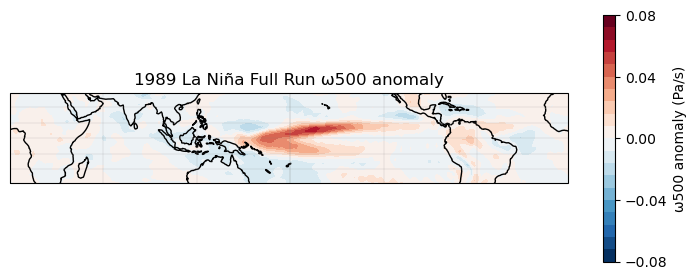

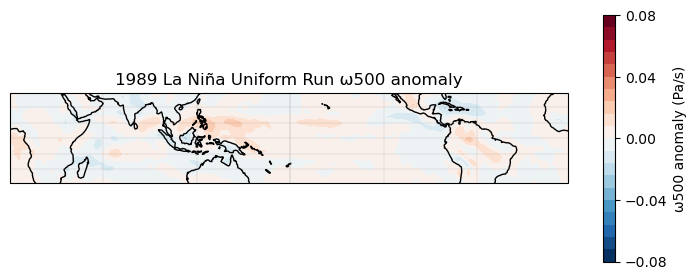

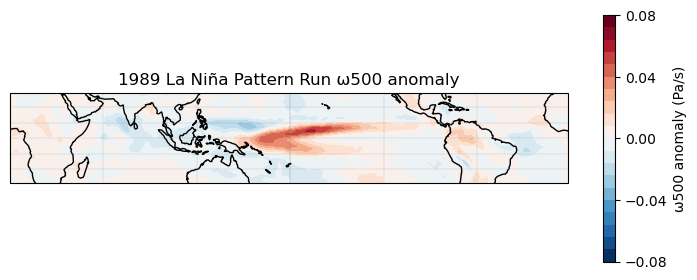

In [7]:
VMIN = None        # <- explicit limits in Pa/s, e.g. VMIN = -0.06, VMAX = 0.06; None = automatic
VMAX = None
N_LEVELS = 21      # shading boundaries (20 bands)
TICK_STEP = 0.02   # Pa/s, used to round VMAX up to a clean value
N_TICKS = 5        # labelled colorbar ticks, symmetric around 0

anomalies = {}
for run in ["Full Run", "Uniform Run", "Pattern Run"]:
    check_path = os.path.join(event_dir(CHECK_EVENT_TYPE), f"{CHECK_EVENT_YEAR}_{RUN_SUFFIX[run]}_echam6_ATM_mm_1976-1999.nc")
    if not os.path.exists(check_path):
        print(f"missing {check_path} -- change CHECK_EVENT_YEAR/CHECK_EVENT_TYPE above")
        continue
    anomalies[run] = restrict_tropics(omega500_field(check_path) - climatology, 30)

if VMAX is None:
    data_vmax = float(max(np.abs(f).max() for f in anomalies.values()))
    VMAX = TICK_STEP * np.ceil(data_vmax / TICK_STEP)
if VMIN is None:
    VMIN = -VMAX

levels = np.linspace(VMIN, VMAX, N_LEVELS)
cbar_ticks = np.linspace(VMIN, VMAX, N_TICKS)

for run, field in anomalies.items():
    show_anomaly_map(field, f"{CHECK_EVENT_YEAR} {CHECK_EVENT_TYPE} {run} ω500 anomaly", levels, cbar_ticks)